# Image Colorization — Data Exploration

This notebook explores the PASCAL VOC 2012 dataset for automatic image colorization.

The analysis focuses on image characteristics, RGB and Lab color spaces, and the preprocessing pipeline used to prepare data for model training.

## 0. Project Setup

Configure project paths and access to the dataset.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
from skimage.color import rgb2lab, lab2rgb

sns.set_context("notebook")

In [ ]:
from pathlib import Path
import sys
# Locate the project root
PROJECT_ROOT = next(
    (
        path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
        if (path / "VOCdevkit" / "VOC2012" / "JPEGImages").is_dir()
    ),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Project root not found. Current directory: {Path.cwd()}"
    )
# Enable imports from the project package
PACKAGE_ROOT = (
    PROJECT_ROOT / "src"
    if (PROJECT_ROOT / "src" / "image_colorization").is_dir()
    else PROJECT_ROOT
)
if str(PACKAGE_ROOT) not in sys.path:
    sys.path.insert(0, str(PACKAGE_ROOT))
# Define dataset paths
IMAGES_DIR = PROJECT_ROOT / "VOCdevkit" / "VOC2012" / "JPEGImages"
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"


## 1. Dataset Overview

We use the **PASCAL VOC 2012** dataset for image colorization.

First, we explore the dataset by examining the number of images, image dimensions, file formats, and average brightness. These characteristics help us determine an appropriate preprocessing strategy for model training.

In [ ]:
image_paths = sorted(IMAGES_DIR.glob("*.jpg"))

if not image_paths:
    raise ValueError(f"No JPEG images found in {IMAGES_DIR}")

print(f"Total images: {len(image_paths):,}")

Total images: 17,125


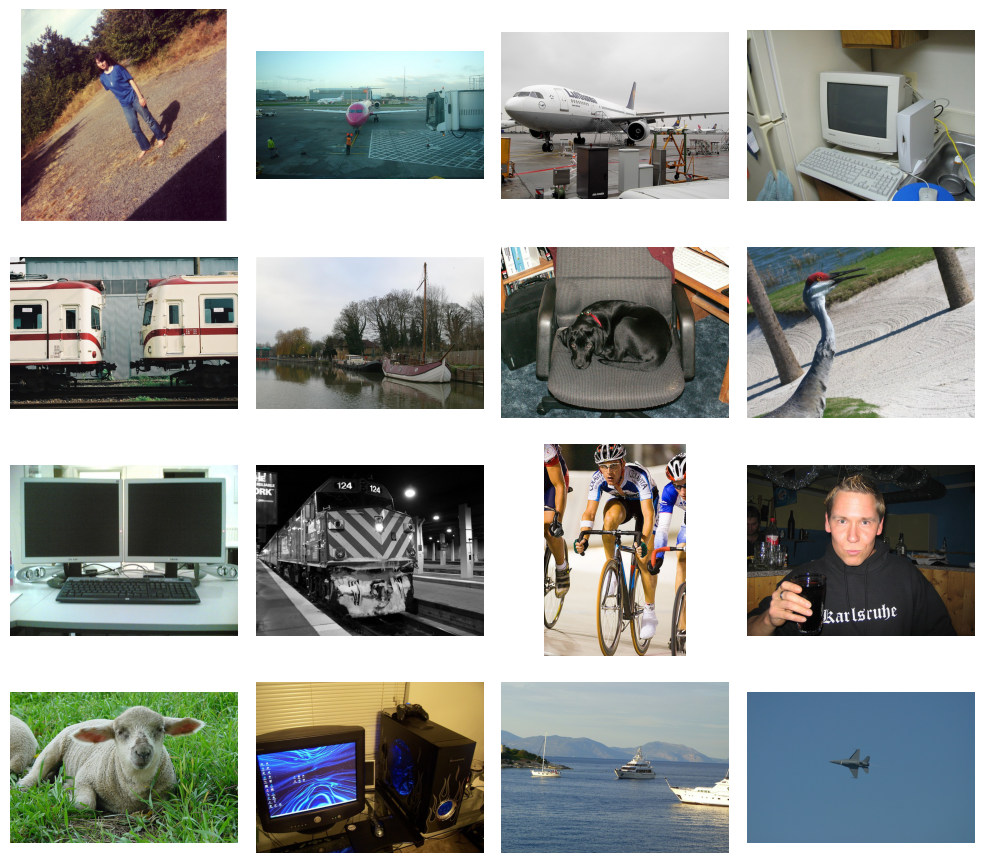

In [ ]:
show_paths = image_paths[:16]
fig, axes = plt.subplots(4, 4, figsize=(10, 9))
for ax, path in zip(axes.flat, show_paths):
    with Image.open(path) as picture:
        ax.imshow(picture.convert("RGB"))
    ax.axis("off")
for ax in list(axes.flat)[len(show_paths):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 1.1. Dataset Characteristics

We examine image dimensions, aspect ratios, color modes, and average brightness to better understand the dataset and identify suitable preprocessing steps for model training.

In [ ]:
records = []

for path in image_paths:
    with Image.open(path) as picture:
        width, height = picture.size
        gray = np.asarray(picture.convert("L"), dtype=np.float32)

        records.append({
            "filename": path.name,
            "width": width,
            "height": height,
            "aspect_ratio": round(width / height, 3),
            "brightness": round(float(gray.mean()), 3),
            "channels": len(picture.getbands()),
            "mode": picture.mode,
            "file_size_kb": round(path.stat().st_size / 1024, 2),
        })

info_df = pd.DataFrame.from_records(records)
info_df["px_count"] = info_df["width"] * info_df["height"]

display(info_df.head())

print("Number of unique channel counts:", info_df["channels"].nunique())
print("Number of unique color modes:", info_df["mode"].nunique())


,filename,width,height,aspect_ratio,brightness,channels,mode,file_size_kb,px_count
0,2007_000027.jpg,486,500,0.972,105.647,3,RGB,142.08,243000
1,2007_000032.jpg,500,281,1.779,125.635,3,RGB,53.47,140500
2,2007_000033.jpg,500,366,1.366,161.763,3,RGB,69.54,183000
3,2007_000039.jpg,500,375,1.333,131.606,3,RGB,63.15,187500
4,2007_000042.jpg,500,335,1.493,121.003,3,RGB,80.91,167500


Number of unique channel counts: 1
Number of unique color modes: 1


### 1.2. Image Dimensions, Brightness, and File Sizes

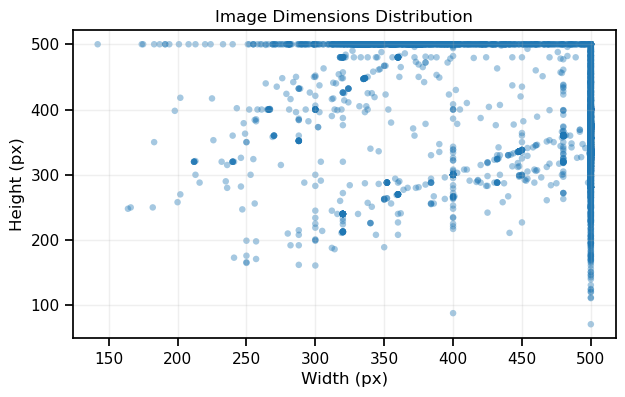

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=info_df, x="width", y="height", s=22,
                edgecolor="none", alpha=0.4, ax=ax)

ax.set(title="Image Dimensions Distribution",
       xlabel="Width (px)", ylabel="Height (px)")
ax.grid(alpha=0.2)
plt.show()


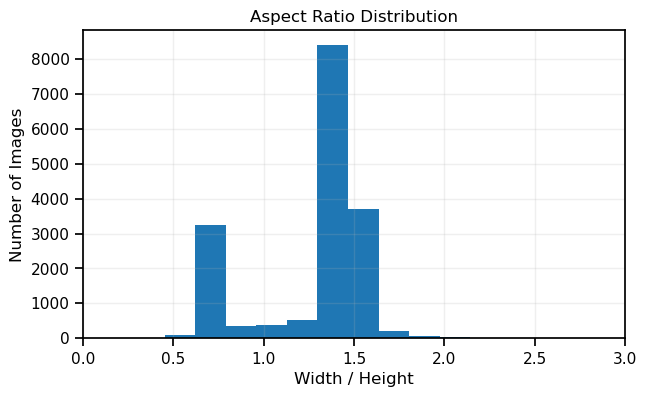

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(info_df["aspect_ratio"].to_numpy(), bins=40)

ax.set(title="Aspect Ratio Distribution",
       xlabel="Width / Height", ylabel="Number of Images")
ax.set_xlim(0, 3)
ax.grid(alpha=0.2)
plt.show()

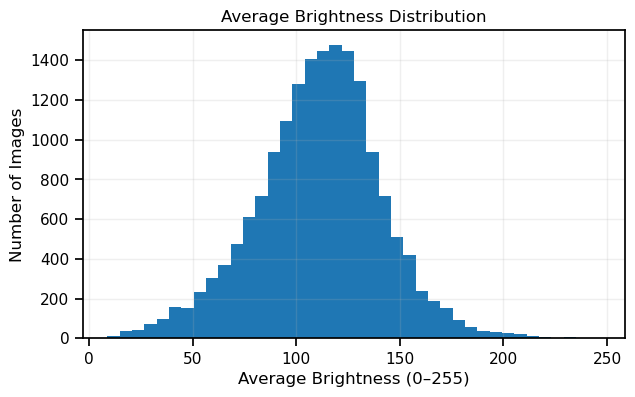

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(info_df["brightness"].to_numpy(), bins=40)

ax.set(title="Average Brightness Distribution",
       xlabel="Average Brightness (0–255)", ylabel="Number of Images")
ax.grid(alpha=0.2)
plt.show()

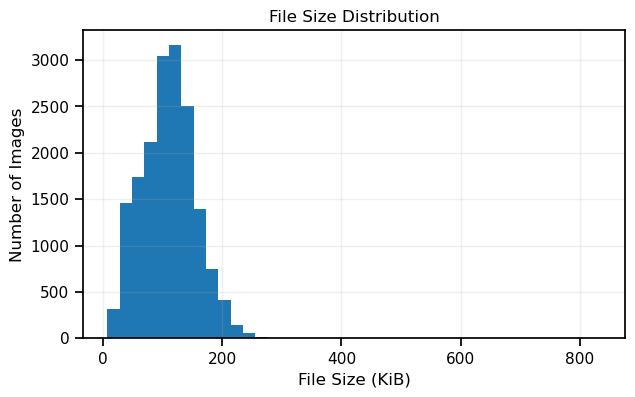

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(info_df["file_size_kb"].to_numpy(), bins=40)

ax.set(title="File Size Distribution",
       xlabel="File Size (KiB)", ylabel="Number of Images")
ax.grid(alpha=0.2)
plt.show()

**Key Observations:**

- Most images have a width or height of approximately 500 pixels.
- Landscape-oriented images are more common, with aspect ratios typically ranging from 1.3 to 1.5.
- Average brightness values frequently range from 75 to 155.
- Most image files range from approximately 30 to 170 KiB.

The variation in image dimensions and aspect ratios highlights the need for consistent image preprocessing before model training.

### 1.3. Examples of Extreme Cases

We examine images with extreme characteristics, including the darkest, brightest, smallest, most vertically oriented, and most horizontally oriented examples.

This helps us understand the diversity of the dataset before resizing and cropping images for model training.

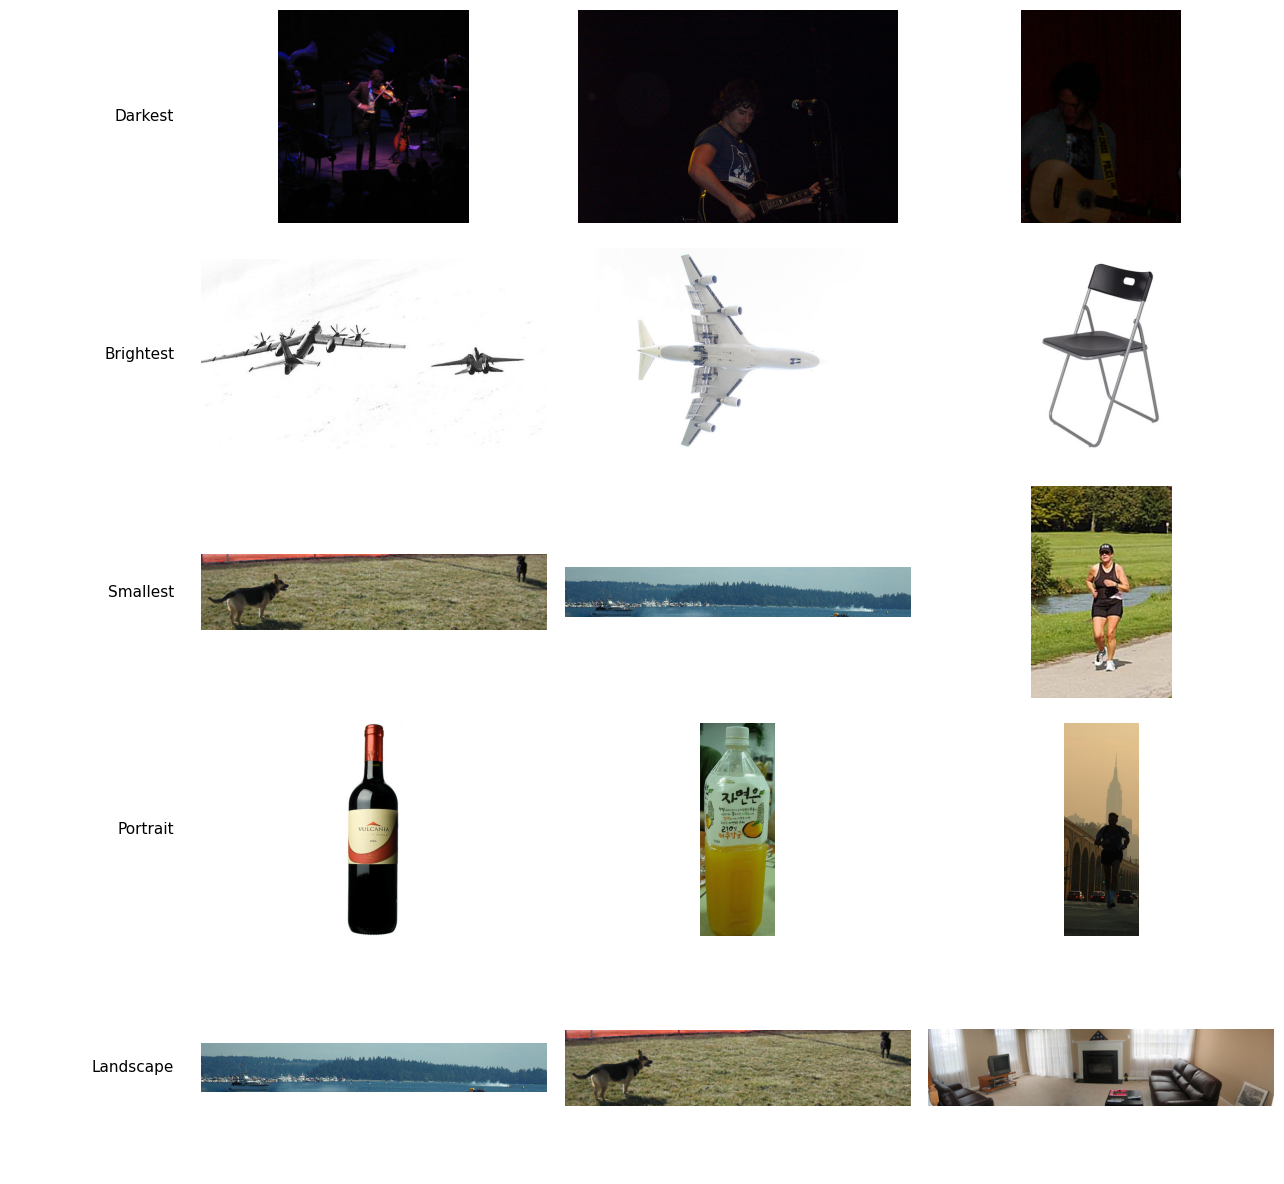

In [ ]:
groups = {
    "Darkest": info_df.nsmallest(3, "brightness")["filename"],
    "Brightest": info_df.nlargest(3, "brightness")["filename"],
    "Smallest": info_df.nsmallest(3, "px_count")["filename"],
    "Portrait": info_df.nsmallest(3, "aspect_ratio")["filename"],
    "Landscape": info_df.nlargest(3, "aspect_ratio")["filename"],
}

path_by_name = {path.name: path for path in image_paths}

fig, axes = plt.subplots(
    5, 4, figsize=(13, 12),
    gridspec_kw={"width_ratios": [1.5, 3, 3, 3]}
)

for row, (label, filenames) in enumerate(groups.items()):
    axes[row, 0].text(
        0.95, 0.5, label,
        ha="right", va="center", fontsize=11
    )
    axes[row, 0].axis("off")

    for col, filename in enumerate(filenames, start=1):
        with Image.open(path_by_name[filename]) as picture:
            axes[row, col].imshow(picture.convert("RGB"))
        axes[row, col].axis("off")

plt.tight_layout(h_pad=1.5)
plt.show()


### 1.4. Train / Validation / Test Split

The dataset is divided into training (70%), validation (15%), and test (15%) sets using `random_state=42` for reproducibility.

If the split files already exist, they are reused to ensure consistent data splits across all experiments.

In [ ]:
split_paths = {name: SPLITS_DIR / f"{name}.txt" for name in ("train", "val", "test")}
existing = {name: path.is_file() for name, path in split_paths.items()}

if all(existing.values()):
    print("Using existing data splits. No files were modified.")
elif any(existing.values()):
    raise FileNotFoundError(
        "Only some split files were found. Check data/splits/ manually. "
        "Automatic overwriting is disabled."
    )
else:
    train_f, remaining_f = train_test_split(
        info_df["filename"], test_size=0.30, random_state=42
    )
    val_f, test_f = train_test_split(
        remaining_f, test_size=0.50, random_state=42
    )
    SPLITS_DIR.mkdir(parents=True, exist_ok=True)
    for name, filenames in zip(("train", "val", "test"), (train_f, val_f, test_f)):
        filenames.to_csv(split_paths[name], index=False, header=False)
    print("Data splits created with random_state=42.")

split_names = {name: path.read_text(encoding="utf-8").splitlines()
               for name, path in split_paths.items()}
for name, filenames in split_names.items():
    print(f"{name:5s}: {len(filenames):5d} images")

train_names, val_names, test_names = [set(split_names[name])
                                      for name in ("train", "val", "test")]

assert not (train_names & val_names or train_names & test_names or val_names & test_names), "Data splits overlap. Check the split files."
assert train_names | val_names | test_names == set(info_df["filename"]), "Split files do not match the current image dataset."
print("Data split validation passed: no overlaps, all images included.")

Using existing data splits. No files were modified.
train: 11987 images
val  :  2569 images
test :  2569 images
Data split validation passed: no overlaps, all images included.


## 2. Color Spaces

### 2.1. RGB and Image Channels

In the RGB color space, each pixel is represented by three components (R, G, B), typically ranging from 0 to 255 for 8-bit images.

In NumPy, images usually have the shape `(H, W, 3)`, while PyTorch commonly uses `(C, H, W)`.

In [ ]:
# Select a sample image from the training set
example_name = split_names["train"][min(1000, len(split_names["train"]) - 1)]
with Image.open(IMAGES_DIR / example_name) as picture:
    rgb_image = picture.convert("RGB")
    rgb_array = np.asarray(rgb_image)

print("Filename:", example_name)
print("NumPy shape:", rgb_array.shape, "dtype:", rgb_array.dtype)
print("Individual channel shapes:", [rgb_array[..., i].shape for i in range(3)])

Filename: 2009_001611.jpg
NumPy shape: (375, 500, 3) dtype: uint8
Individual channel shapes: [(375, 500), (375, 500), (375, 500)]


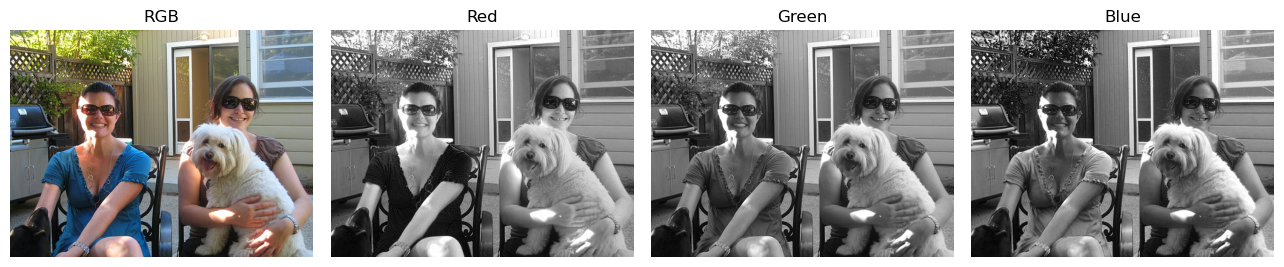

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
axes[0].imshow(rgb_array)
axes[0].set_title("RGB")
for i, name in enumerate(("Red", "Green", "Blue"), start=1):
    axes[i].imshow(rgb_array[:, :, i - 1], cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(name)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.2. Grayscale

Grayscale images contain a single channel instead of three RGB channels.

In Pillow, `convert("L")` performs a weighted conversion of RGB values to grayscale, commonly approximated as `0.299R + 0.587G + 0.114B`.

The resulting grayscale image is not equivalent to the L channel of the Lab color space, which will be used as input to our model.

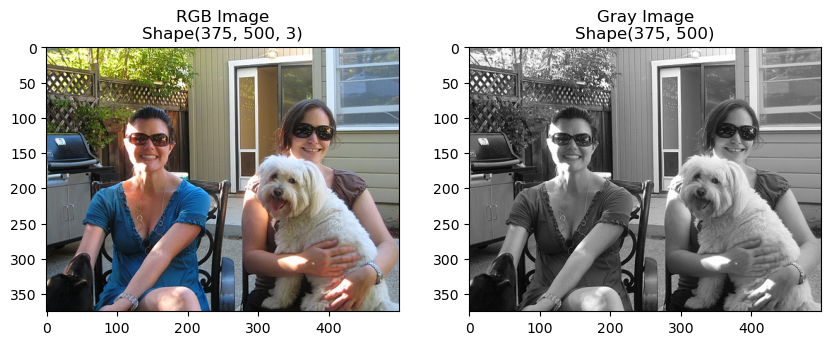

In [ ]:
grayscale_array = np.asarray(rgb_image.convert("L"))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(rgb_array)
axes[0].set_title(f"RGB: {rgb_array.shape}")
axes[1].imshow(grayscale_array, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"PIL grayscale: {grayscale_array.shape}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.3. CIE Lab

The CIE Lab color space separates lightness from color information:

- **L:** lightness
- **a:** green–red axis
- **b:** blue–yellow axis

Following the approach described in *Colorful Image Colorization*, the task is to predict the ab color channels from the input lightness channel L.

We use `skimage.color.rgb2lab` to convert RGB images into Lab color space.

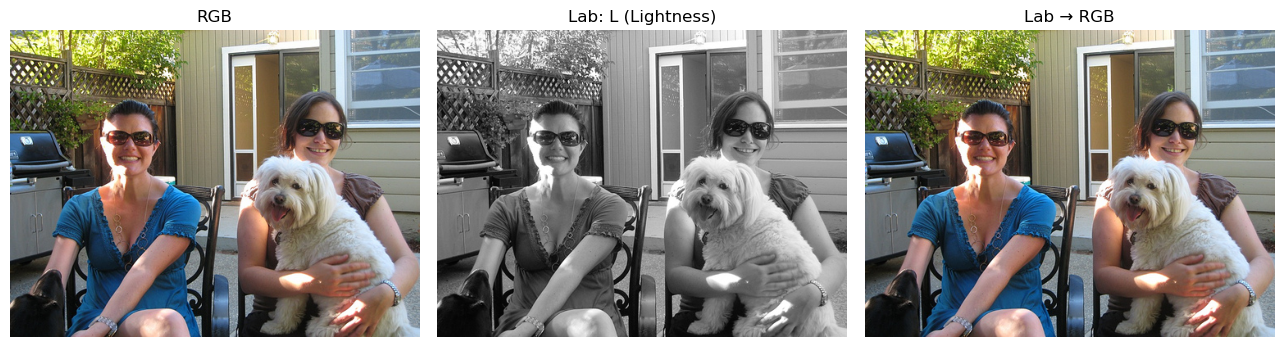

L range: 0.00 ↔ 100.00
a range: -38.21 ↔ 58.29
b range: -58.40 ↔ 83.73


In [ ]:
lab_image = rgb2lab(rgb_array)
L_channel, a_channel, b_channel = [lab_image[..., i] for i in range(3)]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(rgb_array)
axes[0].set_title("RGB")
axes[1].imshow(L_channel, cmap="gray", vmin=0, vmax=100)
axes[1].set_title("Lab: L (Lightness)")
axes[2].imshow(lab2rgb(lab_image))
axes[2].set_title("Lab → RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"L range: {L_channel.min():.2f} ↔ {L_channel.max():.2f}")
print(f"a range: {a_channel.min():.2f} ↔ {a_channel.max():.2f}")
print(f"b range: {b_channel.min():.2f} ↔ {b_channel.max():.2f}")


### 2.4. Normalization and Reconstruction

The Lab channels are normalized using fixed scaling factors:

- **L:** L / 100
- **a:** a / 128
- **b:** b / 128

This scales L to [0, 1] and keeps ab values approximately within [-1, 1].

To verify the preprocessing pipeline, we reconstruct the original RGB image from the normalized Lab representation and measure the reconstruction error.

In [ ]:

from image_colorization.color_utils import denormalize_lab, prepare_lab

L_norm, ab_norm = prepare_lab(rgb_array)
lab_restored = denormalize_lab(L_norm, ab_norm)
rgb_restored = lab2rgb(lab_restored)

rgb_float = rgb_array.astype(np.float64) / 255.0
error = np.abs(rgb_float - rgb_restored)

print("L shape:", L_norm.shape, "ab shape:", ab_norm.shape)
print("L range:", (float(L_norm.min()), float(L_norm.max())))
print("ab range:", (float(ab_norm.min()), float(ab_norm.max())))
print("Maximum RGB reconstruction error:", float(error.max()))
print("Mean RGB reconstruction error:", float(error.mean()))

assert error.max() < 1e-3, "RGB → Lab → RGB reconstruction check failed."


L shape: (375, 500) ab shape: (375, 500, 2)
L range: (0.0, 1.0)
ab range: (-0.45622104112549977, 0.6541359444895553)
Maximum RGB reconstruction error: 6.029773672172611e-07
Mean RGB reconstruction error: 1.8020920868726554e-12


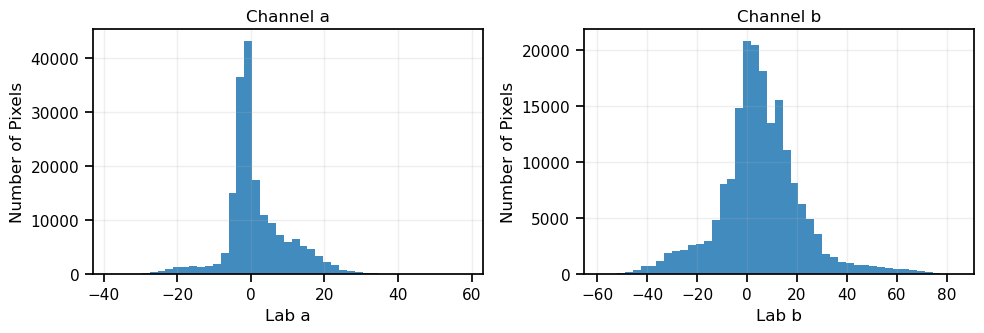

In [ ]:
# Examine the distribution of a and b channel values for the selected image
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, values, channel in zip(axes, (a_channel, b_channel), ("a", "b")):
    ax.hist(values.ravel(), bins=45, alpha=0.85)
    ax.set(xlabel=f"Lab {channel}", ylabel="Number of Pixels", title=f"Channel {channel}")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Dataset and DataLoader

Each training sample consists of a pair `(L, ab)`:

- **L:** `(1, 128, 128)` — normalized lightness channel used as model input.
- **ab:** `(2, 128, 128)` — target color channels.

The preprocessing pipeline converts images to RGB, applies resizing and center cropping, transforms them into Lab color space, and normalizes the resulting channels.

We verify the output shapes and data types before training.

In [ ]:
from image_colorization.dataloaders import create_dataloaders

BATCH_SIZE = 32
IMAGE_SIZE = 128

train_loader, val_loader = create_dataloaders(
    images_dir=IMAGES_DIR,
    train_path=split_paths["train"],
    val_path=split_paths["val"],
    batch_size=BATCH_SIZE,
    num_workers=0,  # For compatibility with Jupyter and different operating systems
    image_size=IMAGE_SIZE,
)

train_L, train_ab = next(iter(train_loader))
L_batch, ab_batch = next(iter(val_loader))
print("Train:", tuple(train_L.shape), tuple(train_ab.shape))
print("Val:  ", tuple(L_batch.shape), tuple(ab_batch.shape))

assert train_L.shape[1:] == (1, IMAGE_SIZE, IMAGE_SIZE)
assert train_ab.shape[1:] == (2, IMAGE_SIZE, IMAGE_SIZE)
assert L_batch.shape[1:] == (1, IMAGE_SIZE, IMAGE_SIZE)
assert ab_batch.shape[1:] == (2, IMAGE_SIZE, IMAGE_SIZE)
assert train_L.dtype == train_ab.dtype == torch.float32


Train: (32, 1, 128, 128) (32, 2, 128, 128)
Val:   (32, 1, 128, 128) (32, 2, 128, 128)


### 3.1. Batch Visualization

We compare the input lightness channel with the RGB image reconstructed from the ground-truth ab channels.

These are not model predictions. This step verifies that image loading, preprocessing, and color space reconstruction work correctly.

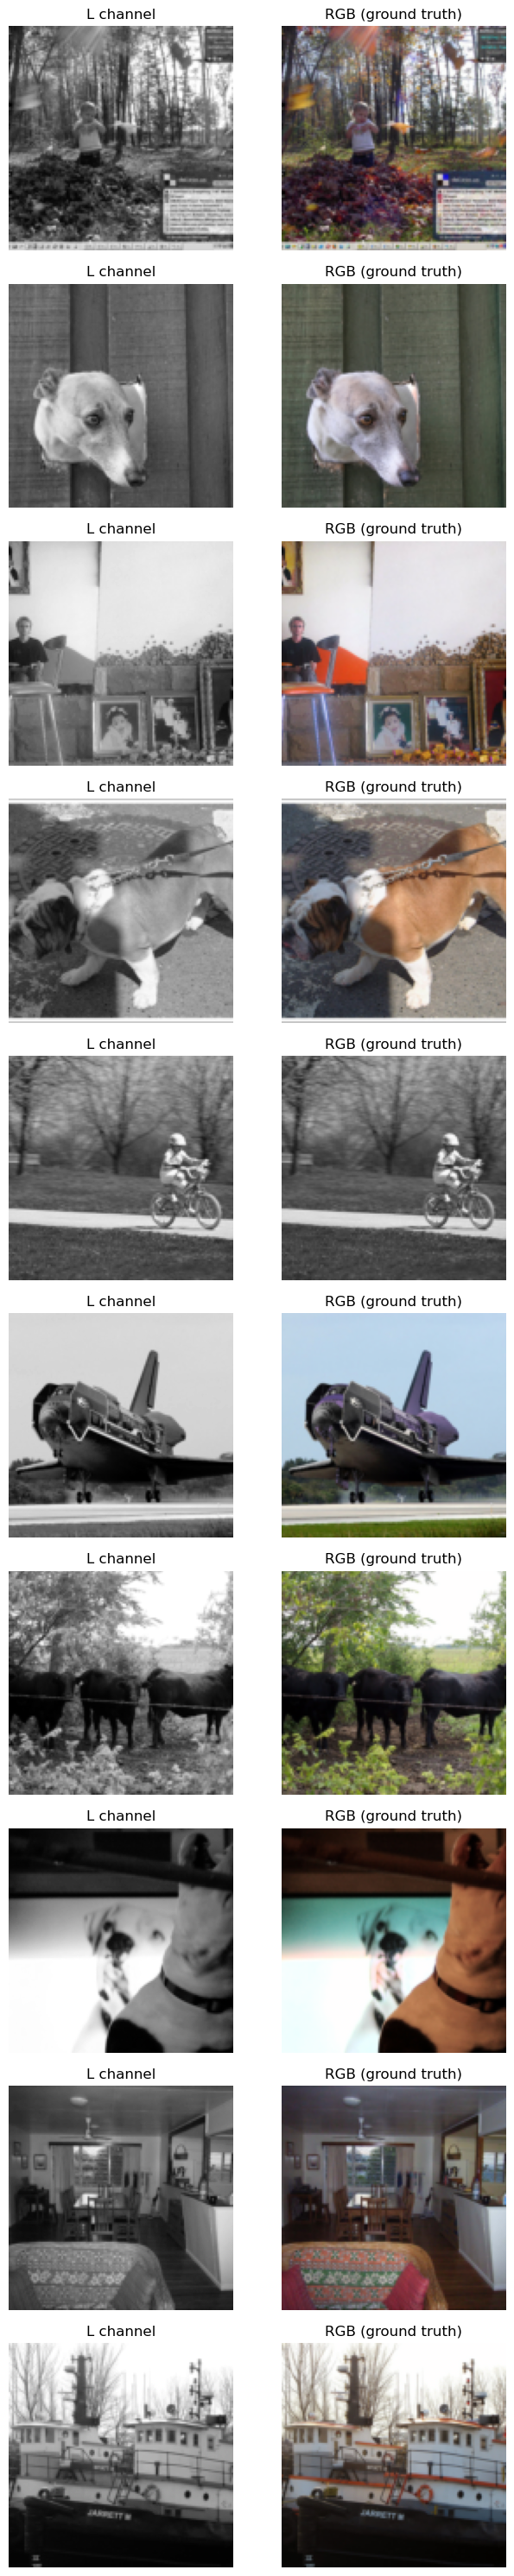

In [ ]:
n_show = min(10, len(L_batch))
fig, axes = plt.subplots(n_show, 2, figsize=(7, 3 * n_show), squeeze=False)

for i in range(n_show):
    L = L_batch[i, 0].numpy()
    ab = ab_batch[i].permute(1, 2, 0).numpy()
    restored_rgb = lab2rgb(denormalize_lab(L, ab))

    axes[i, 0].imshow(L, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title("L channel")
    axes[i, 1].imshow(np.clip(restored_rgb, 0, 1))
    axes[i, 1].set_title("RGB (ground truth)")
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# Basic checks for value ranges and sample validity
assert torch.isfinite(L_batch).all() and torch.isfinite(ab_batch).all()
assert float(L_batch.min()) >= -1e-5 and float(L_batch.max()) <= 1 + 1e-5
assert torch.allclose(L_batch[0], L_batch[0].clamp(0, 1), atol=1e-5)

print("Batch shapes, data types, finite values, and L range: OK")


Batch shapes, data types, finite values, and L range: OK


## 4. Conclusions

- PASCAL VOC 2012 contains images with varying dimensions and aspect ratios, requiring consistent preprocessing.
- The dataset is divided into fixed training, validation, and test sets (70/15/15) for reproducible experiments.
- The Lab color space separates lightness from chromatic information, allowing the model to predict ab channels from L.
- Normalization and inverse color transformations were verified through RGB reconstruction.
- The data pipeline produces tensors of shape `(B, 1, 128, 128)` for L and `(B, 2, 128, 128)` for ab.

The prepared dataset can now be used to train and evaluate image colorization models.